# Dendrograms, Ready-to-use

In [5]:
import os
os.chdir("D:/Projets_python/Pardon my French Project/PardonMyFrench")

In [6]:
#Can take up to 1 min
import score_utils as scoring
import comparing_and_showing as cs
import matplotlib.pyplot as plt
import pandas as pd
import chunking
import numpy as np
from sklearn.decomposition import PCA

from scipy.cluster.hierarchy import fcluster
from scipy.spatial.distance import squareform, pdist
from scipy.linalg import norm as normalize_l2
from scipy.spatial import distance_matrix as dm
from scipy.cluster.hierarchy import linkage, dendrogram, cophenet
from scipy.spatial.distance import squareform, pdist

from sklearn.metrics import fowlkes_mallows_score

from copy import deepcopy

In [7]:
linkages = dict()
ids = dict()


In [8]:
import gc
gc.collect()
artistes = os.listdir("Corpus")
scorers = scoring.available_metrics



for a in artistes :
    print(a)
    l1 = 1
    l2 = 0 
    path = f"Corpus/{a}/{a}_songs"

    while l1 != l2 : 
        dnb = chunking.artist_folder_to_artist_df(path)
        personas = pd.unique(dnb["persona_id"])
        total_chunks = dict()
        
        for p in personas :
            c_p_lines = dnb[dnb["persona_id"] == p] #On récupère les lines de persona p
            
            shuffled_p_lines = c_p_lines.sample(frac=1).reset_index(drop=True) #Randomise
            new_chunks = chunking.format_chunk_for_scoring(shuffled_p_lines, persona_id = p, chunk_tokens_nb=200, lang="en")
            total_chunks.update(new_chunks) #On ajoute les lignes

        l1 = len(total_chunks)

        db = cs.create_baseline(path)
        
        personas = pd.unique(db["persona_id"])
        total_chunks = dict()

        for p in personas :
            c_p_lines = db[db["persona_id"] == p] #On récupère les lines de persona p
            
            shuffled_p_lines = c_p_lines.sample(frac=1).reset_index(drop=True) #Randomise
            new_chunks = chunking.format_chunk_for_scoring(shuffled_p_lines, persona_id = p, chunk_tokens_nb=200, lang="en")
            total_chunks.update(new_chunks) #On ajoute les lignes

        l2 = len(total_chunks)
        print(l1, l2)
    
    d, l = cs.get_aggregated_results(path, scorers=scorers, verbose=False)
    l1 = len(l)
    ids[f"{a}"] = l
    linkages[f"{a}"] = {s : linkage(d[s], method='average') for s in d}
    gc.collect()

    d, l = cs.get_aggregated_results("", scorers=scorers, verbose=False, optional_df=db)
    l2 = len(l)
    ids[f"{a}_baseline"] = l
    linkages[f"{a}_baseline"] = {s : linkage(d[s], method='average') for s in d}
    gc.collect()


Beyonce
8 8
Eminem
12 12


KeyboardInterrupt: 

In [ ]:
ids = {k : list(map(lambda x : cs.get_root(x), ids[k])) for k in ids}

In [ ]:
ari_res = {a : dict() for a in artistes[0:1]}
ari_base = {a : dict() for a in artistes[0:1]}

In [ ]:
def get_n_personas(a) : 
    return len(chunking.artist_folder_to_artist_df(f"Corpus/{a}/{a}_songs")["persona_id"].unique())

In [ ]:
from sklearn.metrics import adjusted_rand_score
for a in artistes : 
    n_personas = get_n_personas(a)
    b = a+"_baseline"
    for s in linkages[a] :
        results = fcluster(linkages[a][s], t=n_personas, criterion="maxclust")
        baseline = fcluster(linkages[b][s], t=n_personas, criterion="maxclust")
        id_results = ids[a]
        id_baseline = ids[a+"_baseline"]
        ari_res[a][s] = adjusted_rand_score(id_results, results)
        ari_base[a][s] = adjusted_rand_score(id_baseline, baseline)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def heatmap(X, xlabels=None, ylabels=None, cmap="viridis_r",
            title=None, annotate=True, fmt=".2f", cbar_label=None):
    X = np.asarray(X)
    n_rows, n_cols = X.shape  # ici 8 x 11

    # Labels par défaut : indices
    xlabels = xlabels if xlabels is not None else list(range(n_cols))
    ylabels = ylabels if ylabels is not None else list(range(n_rows))

    assert len(xlabels) == n_cols, f"xlabels doit avoir {n_cols} éléments"
    assert len(ylabels) == n_rows, f"ylabels doit avoir {n_rows} éléments"

    fig, ax = plt.subplots(figsize=(10, 6))
    im = ax.imshow(X, cmap=cmap, aspect="auto")

    # Labels personnalisés
    ax.set_xticks(np.arange(n_cols))
    ax.set_yticks(np.arange(n_rows))
    ax.set_xticklabels(xlabels, rotation=45, ha="right")
    ax.set_yticklabels(ylabels)

    # Valeurs dans les cases
    if annotate:
        seuil = (X.max() + X.min()) / 2
        for i in range(n_rows):
            for j in range(n_cols):
                ax.text(j, i, format(X[i, j], fmt), ha="center", va="center",
                        color="white" if X[i, j] > seuil else "black", fontsize=8)

    cbar = fig.colorbar(im, ax=ax)
    if cbar_label:
        cbar.set_label(cbar_label)
    if title:
        ax.set_title(title)

    fig.tight_layout()
    return fig, ax

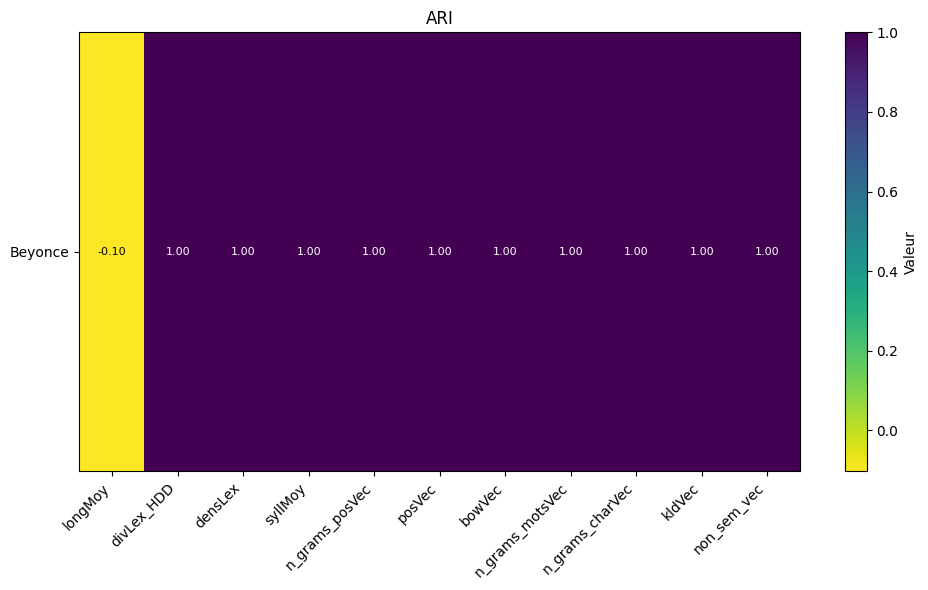

In [ ]:
X = np.array([[ari_base[a][u] for u in ari_base[a]] for a in ari_res])
xlabels = list(ari_base[artistes[0]].keys())   # 11 labels en abscisse
ylabels = artistes  # 8 labels en ordonnée

heatmap(X, xlabels=xlabels, ylabels=ylabels, title="ARI BASE", cbar_label="Valeur")
plt.show()

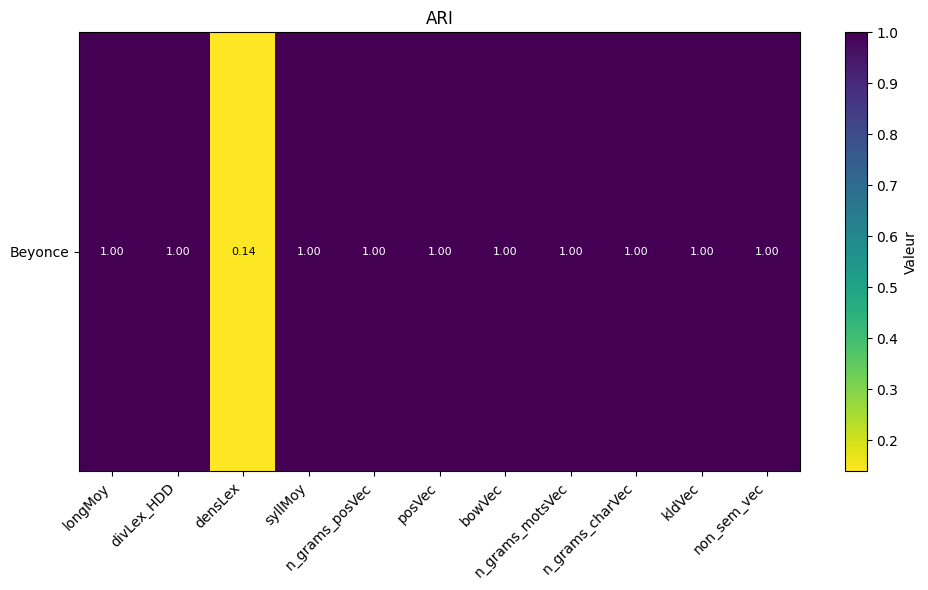

In [ ]:
X = np.array([[ari_res[a][u] for u in ari_res[a]] for a in ari_res])
xlabels = list(ari_res[artistes[0]].keys())   # 11 labels en abscisse
ylabels = artistes # 8 labels en ordonnée

heatmap(X, xlabels=xlabels, ylabels=ylabels, title="ARI RES", cbar_label="Valeur")
plt.show()

In [ ]:
X = np.array([[ari_res[a][u] - ari_base[a][u] for u in ari_base[a]] for a in ari_res])
xlabels = list(ari_base[artistes[0]].keys())   # 11 labels en abscisse
ylabels = artistes  # 8 labels en ordonnée

heatmap(X, xlabels=xlabels, ylabels=ylabels, title="ARI DIFF", cbar_label="Valeur")
plt.show()

In [ ]:
for a in artistes[0:1] : 
    n_personas = get_n_personas(a)
    b = a+"_baseline"
    for s in linkages[a] :
        results = fcluster(linkages[a][s], t=n_personas, criterion="maxclust")
        baseline = fcluster(linkages[b][s], t=n_personas, criterion="maxclust")
        id_results = ids[a]
        id_baselin = ids[a+"_baseline"]
        e_sim = {a : dict() for a in artistes}
        print(s, 'baseline ari :', adjusted_rand_score(id_baselin, baseline), 'result ari : ', adjusted_rand_score(results, id_results))

longMoy baseline ari : -0.10344827586206896 result ari :  1.0
divLex_HDD baseline ari : 1.0 result ari :  1.0
densLex baseline ari : 1.0 result ari :  0.13846153846153847
syllMoy baseline ari : 1.0 result ari :  1.0
n_grams_posVec baseline ari : 1.0 result ari :  1.0
posVec baseline ari : 1.0 result ari :  1.0
bowVec baseline ari : 1.0 result ari :  1.0
n_grams_motsVec baseline ari : 1.0 result ari :  1.0
n_grams_charVec baseline ari : 1.0 result ari :  1.0
kldVec baseline ari : 1.0 result ari :  1.0
non_sem_vec baseline ari : 1.0 result ari :  1.0


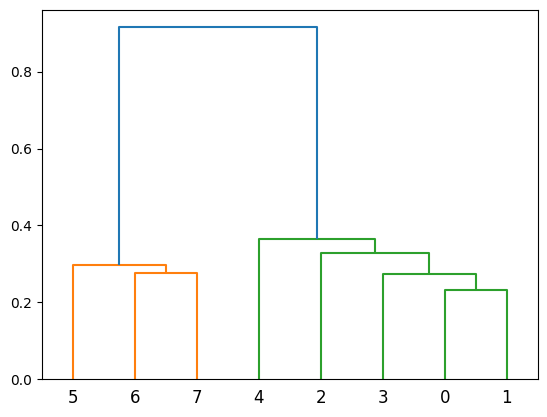

In [37]:
u = dendrogram(linkages['Beyonce_baseline']['bowVec'])

In [32]:
ids['Beyonce_baseline']

['AAAA', 'AAAA', 'AAAA', 'AAAA', 'AAAA', 'BBBB', 'BBBB', 'BBBB']

In [38]:
results

array([1, 1, 1, 1, 2, 1, 1, 1], dtype=int32)

In [39]:
from sklearn.metrics import adjusted_rand_score

In [48]:
adjusted_rand_score([1,1,1,1,1,0,0,0], ids['Beyonce_baseline'])

1.0

In [ ]:
fmi = {a : dict() for a in artistes}
e_sim = {a : dict() for a in artistes}

In [ ]:
from clusim.clustering import Clustering, remap2match
import clusim.sim as sim

In [ ]:
for a in artistes : 
    n_personas = get_n_personas(a)
    b = a+"_baseline"
    for s in linkages[a] :
        c1 = Clustering().from_scipy_linkage(linkages[a][s])
        c2 = Clustering().from_scipy_linkage(linkages[b][s])
        results = fcluster(linkages[a][s], t=n_personas, criterion="maxclust")
        baseline = fcluster(linkages[b][s], t=n_personas, criterion="maxclust")
        fmi[a][s] = fowlkes_mallows_score(results, baseline)
        e_sim[a][s] = sim.element_sim(c1, c2, r=1.0, alpha=0.9)

In [64]:
X = np.array([[e_sim[a][u] for u in e_sim[a]] for a in fmi])
X = (X-X.min())/(X.max()-X.min())
xlabels = list(e_sim[artistes[0]].keys())   # 11 labels en abscisse
ylabels = artistes  # 8 labels en ordonnée

heatmap(X, xlabels=xlabels, ylabels=ylabels, title="Element-centric similarity between artist and baseline", cbar_label="Valeur")
plt.show()

NameError: name 'fmi' is not defined

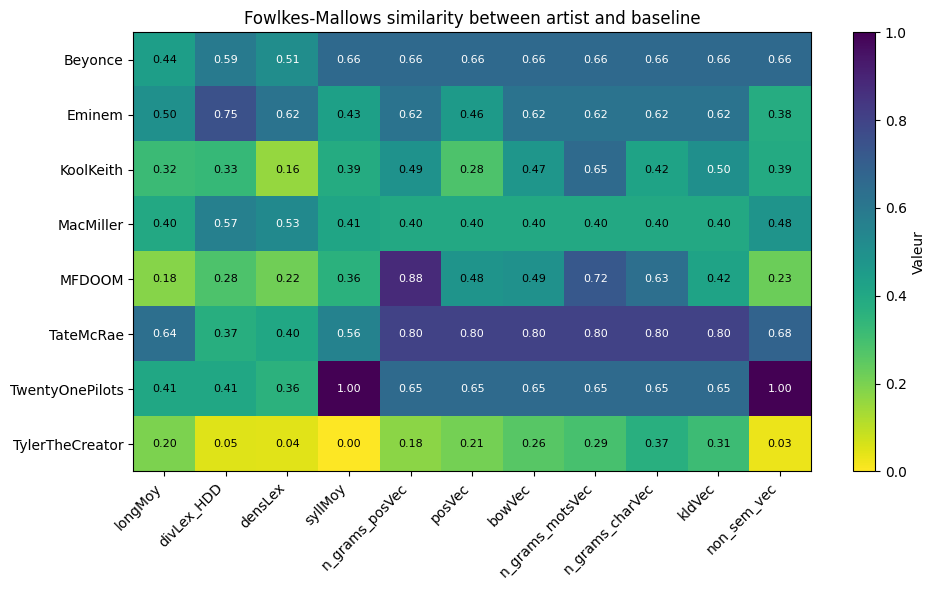

In [93]:
# --- Exemple d'utilisation ---
X = np.array([[fmi[a][u] for u in fmi[a]] for a in fmi])
X = (X-X.min())/(X.max()-X.min())
xlabels = list(fmi[artistes[0]].keys())   # 11 labels en abscisse
ylabels = artistes  # 8 labels en ordonnée

heatmap(X, xlabels=xlabels, ylabels=ylabels, title="Fowlkes-Mallows similarity between artist and baseline", cbar_label="Valeur")
plt.show()

In [57]:
fcluster(linkages["Beyonce"]['bowVec'], t=2, criterion="maxclust")

array([1, 1, 1, 2, 2, 2, 2, 2], dtype=int32)

In [58]:
fcluster(linkages["Beyonce_baseline"]['bowVec'], t=2, criterion="maxclust")

array([1, 1, 1, 1, 2, 2, 2, 2], dtype=int32)

In [64]:
y = [0,0,0,0,2,2,2,2,1,1,1,1,3,3,3,3]

In [62]:
y2 = [1,1,1,1,2,2,2,3,2,3,3,3,0,0,0,0]

In [63]:
fowlkes_mallows_score(y, y2)

0.7499999999999999

In [ ]:
fowlkes_mallows_score([0,1,2,2,2,2], [0,2,1,1,1,1])


1.0